# MarketMind — Experiment 5: Multi-Timeframe Regime Analysis

## Objective
Test whether combining information from different completed candle intervals improves market-regime discovery at a 15-minute decision point.

We compare:
- 15-minute features only
- 15-minute + 30-minute features
- 15-minute + 60-minute features
- 15-minute + 30-minute + 60-minute features

Models:
- K-Means (4 clusters)
- Gaussian Mixture Model (4 components)
- Gaussian HMM (4 hidden states)

## Critical timing rule
A higher-timeframe candle is only usable **after it has closed**. For example, a 60-minute candle beginning at 09:15 is not available at 09:30; it becomes available at 10:15. We use backward as-of joins on candle completion timestamps to prevent look-ahead leakage.

All feature engineering is trailing. Scalers are fitted on training data only. The split is chronological. HMM test-state probabilities are calculated with forward filtering and sequences reset each trading session.

There are no independent ground-truth regime labels. Internal clustering metrics are diagnostics, not prediction accuracy. This experiment does not establish trading profitability.

## 0. Install dependencies

In [1]:
%pip install -q numpy pandas matplotlib scikit-learn hmmlearn scipy

Note: you may need to restart the kernel to use updated packages.


## 1. Imports and locate the MarketMind project automatically

In [2]:
from pathlib import Path
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from hmmlearn.hmm import GaussianHMM
from scipy.special import logsumexp

RANDOM_STATE = 42
TRAIN_FRACTION = 0.70
N_STATES = 4
METRIC_SAMPLE_SIZE = 6000

cwd = Path.cwd().resolve()
ROOT = next((p for p in [cwd, *cwd.parents]
             if (p / "data" / "raw" / "nifty50" / "1min").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError(
        "Could not find MarketMind/data/raw/nifty50/1min. "
        f"Current directory: {cwd}. Save this notebook in MarketMind/research."
    )

DATA_DIR = ROOT / "data" / "raw" / "nifty50" / "1min"
OUT_DIR = ROOT / "research" / "multi_timeframe_results"
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Project:", ROOT)
print("Data:", DATA_DIR)

Project: D:\College_Stuff\Sem_5\Machine_Learning\CP\final\2\MarketMind
Data: D:\College_Stuff\Sem_5\Machine_Learning\CP\final\2\MarketMind\data\raw\nifty50\1min


## 2. Load and clean the historical one-minute OHLC files

In [3]:
files = sorted(DATA_DIR.rglob("*.csv"))
if not files:
    raise FileNotFoundError(f"No CSV files found under {DATA_DIR}")

required = ["Timestamp", "Open", "High", "Low", "Close"]
frames = []
for path in files:
    part = pd.read_csv(path)
    if not set(required).issubset(part.columns):
        continue
    part = part[required].copy()
    part["Timestamp"] = pd.to_datetime(part["Timestamp"], errors="coerce")
    for c in ["Open", "High", "Low", "Close"]:
        part[c] = pd.to_numeric(part[c], errors="coerce")
    frames.append(part)

if not frames:
    raise ValueError("No CSV files contained the required OHLC columns.")

raw = pd.concat(frames, ignore_index=True).dropna(subset=required)
raw = raw.sort_values("Timestamp").drop_duplicates("Timestamp", keep="first")
raw = raw[(raw[["Open","High","Low","Close"]] > 0).all(axis=1)]
raw = raw[raw["High"] >= raw[["Open","Close","Low"]].max(axis=1)]
raw = raw[raw["Low"] <= raw[["Open","Close","High"]].min(axis=1)]
raw = raw.set_index("Timestamp").sort_index().between_time("09:15","15:29")
raw["session"] = raw.index.date

print("Files:", len(files))
print("Clean one-minute rows:", f"{len(raw):,}")
print("Coverage:", raw.index.min(), "to", raw.index.max())

Files: 20
Clean one-minute rows: 890,607
Coverage: 2017-04-03 09:15:00 to 2026-11-17 15:29:00


## 3. Build session-aligned 15m, 30m and 60m candles
Each session is resampled separately from 09:15. Incomplete higher-timeframe bars are excluded. The last partial 60-minute segment is not treated as a full 60-minute candle.

In [4]:
def make_timeframe_bars(raw_df, minutes):
    rule = f"{minutes}min"
    expected = minutes
    pieces = []
    for session, group in raw_df.groupby("session"):
        g = group.drop(columns=["session"]).sort_index()
        rs = g.resample(
            rule, origin="start_day", offset="9h15min",
            label="left", closed="left"
        )
        out = rs.agg({
            "Open": "first", "High": "max",
            "Low": "min", "Close": "last"
        })
        counts = rs["Close"].count()
        out["observed_minutes"] = counts
        # Require at least 80% of expected minute observations.
        out = out[out["observed_minutes"] >= int(np.ceil(expected * 0.8))]
        out = out.dropna(subset=["Open","High","Low","Close"])
        pieces.append(out)
    result = pd.concat(pieces).sort_index()
    result = result[~result.index.duplicated(keep="first")]
    return result

bars15 = make_timeframe_bars(raw, 15)
bars30 = make_timeframe_bars(raw, 30)
bars60 = make_timeframe_bars(raw, 60)

print("15m bars:", len(bars15))
print("30m bars:", len(bars30))
print("60m bars:", len(bars60))
display(pd.DataFrame({
    "timeframe": ["15m","30m","60m"],
    "bars": [len(bars15),len(bars30),len(bars60)]
}))

15m bars: 59374
30m bars: 28497
60m bars: 14245


,timeframe,bars
0,15m,59374
1,30m,28497
2,60m,14245


## 4. Calculate causal features independently at each timeframe

In [5]:
def add_features(frame, prefix):
    x = frame[["Open","High","Low","Close"]].copy()
    close = x["Close"]
    prev = close.shift(1)
    logret = np.log(close).diff()
    delta = close.diff()
    gain = delta.clip(lower=0).rolling(14, min_periods=14).mean()
    loss = (-delta.clip(upper=0)).rolling(14, min_periods=14).mean()
    rs = gain / loss.replace(0, np.nan)
    rsi = 100 - 100 / (1 + rs)
    tr = pd.concat([
        x["High"] - x["Low"],
        (x["High"] - prev).abs(),
        (x["Low"] - prev).abs()
    ], axis=1).max(axis=1)
    atr = tr.rolling(14, min_periods=14).mean()

    f = pd.DataFrame(index=x.index)
    f[f"{prefix}_ret_4"] = np.log(close).diff(4) * 100
    f[f"{prefix}_vol_8"] = logret.rolling(8, min_periods=8).std() * 100
    f[f"{prefix}_rsi_14"] = rsi
    f[f"{prefix}_ma_diff_8_20"] = (
        close.rolling(8).mean() / close.rolling(20).mean() - 1
    ) * 100
    f[f"{prefix}_momentum_4"] = (close / close.shift(4) - 1) * 100
    f[f"{prefix}_atr_pct"] = atr / close * 100
    return f.replace([np.inf,-np.inf], np.nan)

f15 = add_features(bars15, "15m")
f30 = add_features(bars30, "30m")
f60 = add_features(bars60, "60m")
print("Features per timeframe:", f15.shape[1], f30.shape[1], f60.shape[1])

Features per timeframe: 6 6 6


## 5. Align higher-timeframe features without look-ahead
15-minute candle timestamps are labels for candle start. The decision time is its end. Higher-timeframe features become available only at their own candle end. `merge_asof(direction='backward')` selects the latest already-completed higher-timeframe candle.

In [6]:
def availability_frame(features, duration_minutes, prefix):
    out = features.copy()
    out = out.reset_index().rename(columns={out.index.name or "index": "bar_start"})
    if "Timestamp" in out.columns:
        out = out.rename(columns={"Timestamp":"bar_start"})
    out["available_at"] = out["bar_start"] + pd.Timedelta(minutes=duration_minutes)
    out = out.drop(columns=["bar_start"])
    return out.sort_values("available_at")

# The 15-minute decision point is the close of each 15-minute bar.
base = f15.copy().reset_index()
base = base.rename(columns={base.columns[0]: "bar_start"})
base["decision_time"] = base["bar_start"] + pd.Timedelta(minutes=15)
base = base.sort_values("decision_time")

a30 = availability_frame(f30, 30, "30m")
a60 = availability_frame(f60, 60, "60m")

aligned = pd.merge_asof(
    base.sort_values("decision_time"),
    a30.sort_values("available_at"),
    left_on="decision_time", right_on="available_at",
    direction="backward"
)
aligned = pd.merge_asof(
    aligned.sort_values("decision_time"),
    a60.sort_values("available_at"),
    left_on="decision_time", right_on="available_at",
    direction="backward"
)
aligned = aligned.drop(columns=["available_at_x","available_at_y"], errors="ignore")
aligned = aligned.set_index("decision_time").sort_index()

cols15 = list(f15.columns)
cols30 = list(f30.columns)
cols60 = list(f60.columns)

# Remove rows before all timeframe indicators have enough history.
all_cols = cols15 + cols30 + cols60
aligned = aligned.replace([np.inf,-np.inf], np.nan).dropna(subset=all_cols)

feature_sets = {
    "15m_only": cols15,
    "15m_plus_30m": cols15 + cols30,
    "15m_plus_60m": cols15 + cols60,
    "15m_plus_30m_plus_60m": cols15 + cols30 + cols60
}
print("Aligned decision rows:", len(aligned))
print("Decision range:", aligned.index.min(), "to", aligned.index.max())
print("Feature dimensions:", {k:len(v) for k,v in feature_sets.items()})
display(aligned[all_cols].head())

Aligned decision rows: 59262
Decision range: 2017-04-07 11:15:00 to 2026-11-17 15:30:00
Feature dimensions: {'15m_only': 6, '15m_plus_30m': 12, '15m_plus_60m': 12, '15m_plus_30m_plus_60m': 18}


,15m_ret_4,15m_vol_8,15m_rsi_14,15m_ma_diff_8_20,15m_momentum_4,15m_atr_pct,30m_ret_4,30m_vol_8,30m_rsi_14,30m_ma_diff_8_20,30m_momentum_4,30m_atr_pct,60m_ret_4,60m_vol_8,60m_rsi_14,60m_ma_diff_8_20,60m_momentum_4,60m_atr_pct
decision_time,,,,,,,,,,,,,,,,,,
2017-04-07 11:15:00,0.018939,0.103871,52.802102,0.021946,0.018941,0.166302,-0.255599,0.161301,50.000000,0.011958,-0.255273,0.186824,0.173292,0.230565,51.222981,0.021546,0.173443,0.277669
2017-04-07 11:30:00,-0.147695,0.053218,52.434783,0.020769,-0.147586,0.167140,-0.255599,0.161301,50.000000,0.011958,-0.255273,0.186824,0.173292,0.230565,51.222981,0.021546,0.173443,0.277669
2017-04-07 11:45:00,-0.037323,0.058191,54.849360,0.019508,-0.037316,0.166827,0.066568,0.160788,57.681941,0.032344,0.066590,0.177377,0.173292,0.230565,51.222981,0.021546,0.173443,0.277669
2017-04-07 12:00:00,-0.122852,0.068679,41.296296,0.011445,-0.122776,0.146174,0.066568,0.160788,57.681941,0.032344,0.066590,0.177377,0.173292,0.230565,51.222981,0.021546,0.173443,0.277669
2017-04-07 12:15:00,0.015690,0.077234,50.046425,0.008062,0.015691,0.139999,0.034629,0.160648,57.025547,0.057861,0.034635,0.181075,0.138588,0.200475,52.465596,0.003748,0.138684,0.247887


## 6. Verify higher-timeframe availability timestamps
This check confirms that a selected 30m/60m feature timestamp is not later than the 15m decision time.

In [7]:
# Recreate explicit availability keys for audit.
audit_base = f15.copy().reset_index()
audit_base = audit_base.rename(columns={audit_base.columns[0]: "bar_start"})
audit_base["decision_time"] = audit_base["bar_start"] + pd.Timedelta(minutes=15)

def availability_only(features, duration):
    z = features.reset_index()
    z = z.rename(columns={z.columns[0]: "bar_start"})
    z["available_at"] = z["bar_start"] + pd.Timedelta(minutes=duration)
    return z[["available_at"]].sort_values("available_at")

audit = pd.merge_asof(
    audit_base[["decision_time"]].sort_values("decision_time"),
    availability_only(f30, 30),
    left_on="decision_time", right_on="available_at",
    direction="backward"
).rename(columns={"available_at": "available_at_30m"})

audit = pd.merge_asof(
    audit.sort_values("decision_time"),
    availability_only(f60, 60),
    left_on="decision_time", right_on="available_at",
    direction="backward"
).rename(columns={"available_at": "available_at_60m"})

# Compare NumPy arrays positionally. Pandas Series comparisons require
# identical index labels; merge_asof can leave different index labels.
decision_values = audit["decision_time"].to_numpy()
for c in ["available_at_30m", "available_at_60m"]:
    available_values = audit[c].to_numpy()
    valid = pd.notna(available_values)
    assert (
        available_values[valid] <= decision_values[valid]
    ).all(), f"Look-ahead timing detected in {c}"

print("Higher-timeframe availability check passed.")

Higher-timeframe availability check passed.


## 7. Chronological split and model helpers

In [8]:
split = int(len(aligned) * TRAIN_FRACTION)
train = aligned.iloc[:split].copy()
test = aligned.iloc[split:].copy()
assert train.index.max() < test.index.min()

def metrics(X, labels):
    labels = np.asarray(labels)
    if len(np.unique(labels)) < 2 or len(np.unique(labels)) >= len(labels):
        return {"silhouette":np.nan,"davies_bouldin":np.nan,"calinski_harabasz":np.nan}
    return {
        "silhouette":float(silhouette_score(X,labels)),
        "davies_bouldin":float(davies_bouldin_score(X,labels)),
        "calinski_harabasz":float(calinski_harabasz_score(X,labels))
    }

def persistence(states, index):
    s = pd.Series(np.asarray(states), index=index)
    gap = s.index.to_series().diff()
    valid = (gap <= pd.Timedelta(minutes=30)) & s.shift(1).notna()
    return float((s[valid] == s.shift(1)[valid]).mean()*100) if valid.any() else np.nan

def session_lengths(index):
    return pd.Series(1,index=index).groupby(index.date).sum().astype(int).tolist()

def hmm_filter(model, X, lengths):
    emission = model._compute_log_likelihood(np.asarray(X,dtype=float))
    log_trans = np.log(np.clip(model.transmat_,1e-300,1.0))
    probs = np.zeros((len(X),model.n_components))
    offset = 0
    for n in lengths:
        end = offset + int(n)
        la = np.log(np.clip(model.startprob_,1e-300,1.0)) + emission[offset]
        la -= logsumexp(la)
        probs[offset] = np.exp(la)
        for t in range(offset+1,end):
            la = emission[t] + logsumexp(la[:,None]+log_trans,axis=0)
            la -= logsumexp(la)
            probs[t] = np.exp(la)
        offset = end
    if offset != len(X):
        raise ValueError("HMM sequence lengths do not match rows.")
    return probs

print("Train rows:",len(train),"Test rows:",len(test))
print("Train:",train.index.min(),"to",train.index.max())
print("Test:",test.index.min(),"to",test.index.max())

Train rows: 41483 Test rows: 17779
Train: 2017-04-07 11:15:00 to 2023-12-29 13:30:00
Test: 2023-12-29 13:45:00 to 2026-11-17 15:30:00


## 8. Compare K-Means, GMM and 4-state HMM across timeframe feature sets
All models use the same chronological test decision timestamps. For HMM, session boundaries reset the state sequence.

In [9]:
results=[]
state_assignments={}

for set_name, cols in feature_sets.items():
    print("\nRunning:",set_name)
    scaler=StandardScaler()
    Xtr=scaler.fit_transform(train[cols].to_numpy(float))
    Xte=scaler.transform(test[cols].to_numpy(float))

    rng=np.random.default_rng(RANDOM_STATE)
    m=min( METRIC_SAMPLE_SIZE, len(Xte) )
    idx=np.sort(rng.choice(len(Xte),size=m,replace=False))
    Xm=Xte[idx]

    km=KMeans(n_clusters=4,n_init=20,random_state=RANDOM_STATE)
    t0=time.perf_counter(); km.fit(Xtr); km_time=time.perf_counter()-t0
    kl=km.predict(Xte)
    results.append({
        "feature_set":set_name,"model":"KMeans","n_features":len(cols),
        **metrics(Xm,kl[idx]),
        "persistence_pct":persistence(kl,test.index),
        "fit_seconds":km_time,
        "min_occupancy_pct":float(pd.Series(kl).value_counts(normalize=True).min()*100),
        "max_occupancy_pct":float(pd.Series(kl).value_counts(normalize=True).max()),
        "heldout_loglik_per_obs":np.nan
    })
    state_assignments[(set_name,"KMeans")]=kl

    gm=GaussianMixture(n_components=4,covariance_type="diag",n_init=3,
                       max_iter=200,reg_covar=1e-5,random_state=RANDOM_STATE)
    t0=time.perf_counter(); gm.fit(Xtr); gm_time=time.perf_counter()-t0
    gl=gm.predict(Xte)
    results.append({
        "feature_set":set_name,"model":"GMM","n_features":len(cols),
        **metrics(Xm,gl[idx]),
        "persistence_pct":persistence(gl,test.index),
        "fit_seconds":gm_time,
        "min_occupancy_pct":float(pd.Series(gl).value_counts(normalize=True).min()*100),
        "max_occupancy_pct":float(pd.Series(gl).value_counts(normalize=True).max()),
        "heldout_loglik_per_obs":float(gm.score(Xte))
    })
    state_assignments[(set_name,"GMM")]=gl

    hmm=GaussianHMM(n_components=N_STATES,covariance_type="diag",n_iter=120,
                    tol=1e-3,random_state=RANDOM_STATE,min_covar=1e-4,
                    implementation="log")
    lengths_tr=session_lengths(train.index)
    lengths_te=session_lengths(test.index)
    t0=time.perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        hmm.fit(Xtr,lengths=lengths_tr)
    hmm_time=time.perf_counter()-t0
    filtered=hmm_filter(hmm,Xte,lengths_te)
    hl=filtered.argmax(axis=1)
    results.append({
        "feature_set":set_name,"model":"GaussianHMM_4state","n_features":len(cols),
        **metrics(Xte[idx],hl[idx]),
        "persistence_pct":persistence(hl,test.index),
        "fit_seconds":hmm_time,
        "min_occupancy_pct":float(pd.Series(hl).value_counts(normalize=True).min()*100),
        "max_occupancy_pct":float(pd.Series(hl).value_counts(normalize=True).max()),
        "heldout_loglik_per_obs":float(hmm.score(Xte,lengths=lengths_te)/len(Xte))
    })
    state_assignments[(set_name,"GaussianHMM_4state")]=hl
    print("HMM converged:",hmm.monitor_.converged,
          "| warnings:",len(caught),"| iterations:",hmm.monitor_.iter)

comparison=pd.DataFrame(results)
display(comparison.sort_values(["model","silhouette"],ascending=[True,False]))


Running: 15m_only
HMM converged: True | warnings: 0 | iterations: 39

Running: 15m_plus_30m
HMM converged: True | warnings: 0 | iterations: 41

Running: 15m_plus_60m
HMM converged: True | warnings: 0 | iterations: 45

Running: 15m_plus_30m_plus_60m
HMM converged: True | warnings: 0 | iterations: 45


,feature_set,model,n_features,silhouette,davies_bouldin,calinski_harabasz,persistence_pct,fit_seconds,min_occupancy_pct,max_occupancy_pct,heldout_loglik_per_obs
1,15m_only,GMM,6,0.196053,1.906973,1110.371353,83.261048,2.049880,3.566005,0.499128,-4.561460
4,15m_plus_30m,GMM,12,0.156847,2.165662,953.262138,88.225296,2.570672,4.162214,0.456662,-8.808271
7,15m_plus_60m,GMM,12,0.136961,2.266767,849.225699,91.126480,2.437450,4.139715,0.439564,-9.326756
10,15m_plus_30m_plus_60m,GMM,18,0.136933,2.274844,890.507778,91.536748,2.595781,4.280331,0.431633,-13.449761
2,15m_only,GaussianHMM_4state,6,0.162406,1.959465,1044.030779,92.187317,48.313410,5.686484,0.417403,-3.780100
5,15m_plus_30m,GaussianHMM_4state,12,0.138194,2.214649,922.296456,92.357285,48.009989,5.371506,0.408178,-7.960136
11,15m_plus_30m_plus_60m,GaussianHMM_4state,18,0.122609,2.316460,866.806550,94.180049,56.469332,4.865291,0.392204,-12.498503
8,15m_plus_60m,GaussianHMM_4state,12,0.116155,2.310352,812.800568,94.297269,54.834568,5.045278,0.387423,-8.378631
0,15m_only,KMeans,6,0.326913,1.032790,1750.068476,87.633337,6.204797,0.421846,0.517239,NaN
3,15m_plus_30m,KMeans,12,0.275247,1.247078,1464.259554,90.851014,0.842843,0.337477,0.535407,NaN


## 9. Save comparison results and plots

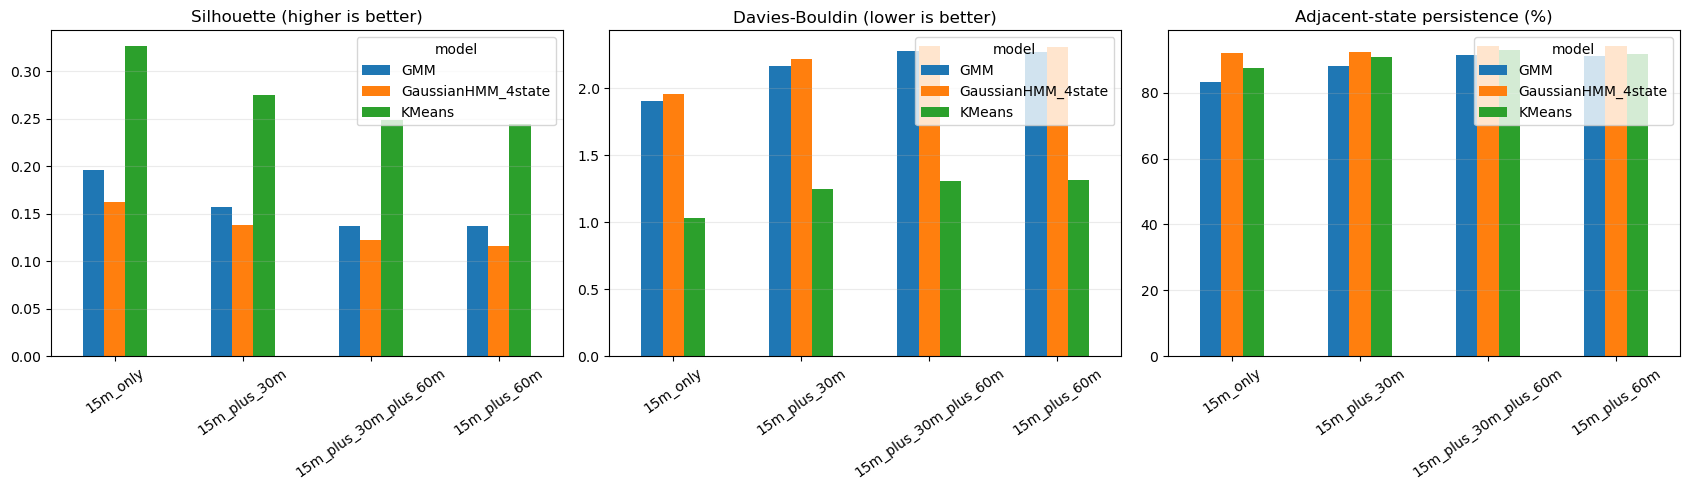

In [10]:
comparison.to_csv(OUT_DIR/"multi_timeframe_model_comparison.csv",index=False)

fig,axes=plt.subplots(1,3,figsize=(17,5))
for ax,metric,title in [
    (axes[0],"silhouette","Silhouette (higher is better)"),
    (axes[1],"davies_bouldin","Davies-Bouldin (lower is better)"),
    (axes[2],"persistence_pct","Adjacent-state persistence (%)")
]:
    comparison.pivot(index="feature_set",columns="model",values=metric).plot(kind="bar",ax=ax)
    ax.set_title(title); ax.set_xlabel(""); ax.tick_params(axis="x",rotation=35)
    ax.grid(axis="y",alpha=.25)
plt.tight_layout(); plt.show()

## 10. Save metadata and limitations

In [11]:
metadata={
    "experiment":"Multi-timeframe regime feature comparison",
    "source":"Bundled NIFTY 50 1-minute OHLC CSV files",
    "decision_timeframe":"15-minute",
    "higher_timeframes":["30-minute","60-minute"],
    "higher_timeframe_alignment":"Backward as-of join on completed candle availability time",
    "chronological_split":"70/30",
    "total_rows":int(len(aligned)),
    "train_rows":int(len(train)),
    "test_rows":int(len(test)),
    "train_start":str(train.index.min()),
    "train_end":str(train.index.max()),
    "test_start":str(test.index.min()),
    "test_end":str(test.index.max()),
    "feature_sets":{k:v for k,v in feature_sets.items()},
    "models":["KMeans_4","GMM_4_diag","GaussianHMM_4state"],
    "limitations":[
        "No independent ground-truth regime labels are available.",
        "Internal clustering metrics are not supervised accuracy.",
        "HMM test labels use causal forward filtering, resetting at session boundaries.",
        "HMM likelihood values across feature dimensions are not directly comparable.",
        "Incomplete higher-timeframe candles are filtered using an 80% observed-minute threshold.",
        "No trading profitability claim is made; transaction-cost-aware walk-forward validation remains necessary."
    ]
}
(OUT_DIR/"multi_timeframe_experiment_metadata.json").write_text(json.dumps(metadata,indent=2))
print("Saved:")
for p in sorted(OUT_DIR.iterdir()):
    print(p.name)

Saved:
multi_timeframe_experiment_metadata.json
multi_timeframe_model_comparison.csv


## 11. Interpretation guide

Compare feature sets **within each model family**:
- Does adding 30-minute context improve on 15m-only?
- Does adding 60-minute context improve on 15m-only?
- Does using both higher timeframes improve further, or add redundant information?
- Are clusters reasonably occupied, or does one cluster dominate?
- Does HMM maintain sensible occupancy and persistence without collapsing into one state?

Do not compare HMM held-out log-likelihood directly across feature sets with different dimensions. Density likelihood depends on feature dimensionality and scaling.

A high persistence score is not automatically good: a model that rarely changes state can look stable but fail to identify meaningful transitions.

